# Обучение автоэнкодера для восстановления изображений лиц

In [ ]:
import pandas as pd
import numpy as np
import torch
from torch import nn
import torchvision.transforms.v2 as transforms
from torch.utils.data import Dataset, DataLoader
import os
import cv2
import matplotlib.pyplot as plt
import torch.nn.functional as F
import copy
import segmentation_models_pytorch as smp

In [ ]:
try:
    import torch_xla
    import torch_xla.core.xla_model as xm
    import torch_xla.distributed.parallel_loader as pl
    device = xm.xla_device()
    is_xla = True
except (ModuleNotFoundError):
    device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else 'cpu'
    is_xla = False

device

In [ ]:
class FaceDataset(Dataset):
    def __init__(self, img_dir, train_size, white_rect, size=5000, is_train=True, transform=None, target_transform=None):
        self.is_train = is_train
        self.transform = transform
        self.target_transform = target_transform
        self.white_rect = white_rect

        self.img_dir = img_dir
        img_filenames = sorted(os.listdir(self.img_dir))[:int(size)]
        self.train_filenames = img_filenames[:int(size * train_size)]
        self.test_filenames = img_filenames[int(size * train_size):]



    def __len__(self):
        if self.is_train:
            return len(self.train_filenames)
        return len(self.test_filenames)

    def __getitem__(self, idx):
        current_imgs = self.train_filenames if self.is_train else self.test_filenames

        img = cv2.imread(os.path.join(self.img_dir, current_imgs[idx]), cv2.IMREAD_COLOR_RGB)
        target = cv2.imread(os.path.join(self.img_dir, current_imgs[idx]), cv2.IMREAD_COLOR_RGB)

        if self.transform:
            #_, x1, y1, w, h = self.bbox_df[self.bbox_df['image_id'] == current_imgs[idx]].iloc[0]
            x1, y1, x2, y2 = self.white_rect
            transform = self.transform(x1, y1, x2, y2)
            img_tr = transform(img)

        if self.target_transform:
            target_tr = self.target_transform(target)
            
        return img_tr, target_tr

In [ ]:
def get_image_with_rect(img, x1, y1, x2, y2):
    image_with_rect = img.copy()

    w = x2 - x1
    h = y2 - y1
    
    rect_w = np.random.randint(20, 30)
    rect_h = np.random.randint(20, 30)
    
    rect_w = min(rect_w, w)
    rect_h = min(rect_h, h)
    
    max_delta_x = max(0, w - rect_w)
    max_delta_y = max(0, h - rect_h)
    
    shift_x = np.random.randint(0, max_delta_x + 1) if max_delta_x > 0 else 0
    shift_y = np.random.randint(0, max_delta_y + 1) if max_delta_y > 0 else 0
    
    pt1 = (x1 + shift_x, y1 + shift_y)
    pt2 = (pt1[0] + rect_w, pt1[1] + rect_h)
    
    cv2.rectangle(image_with_rect, pt1, pt2, (255, 255, 255), -1)
    
    return image_with_rect

In [ ]:
def get_transform(x1, y1, x2, y2):
    return transforms.Compose([
        transforms.Lambda(lambda img: get_image_with_rect(img, x1, y1, x2, y2)),
        transforms.ToImage(),
        transforms.ToDtype(dtype=torch.float32, scale=True)
    ])

target_transform = transforms.Compose([
    transforms.ToImage(),
    transforms.ToDtype(dtype=torch.float32, scale=True)
])

In [ ]:
img_dir = '/kaggle/input/datasets/jessicali9530/celeba-dataset/img_align_celeba/img_align_celeba'

In [ ]:
train_dataset = FaceDataset(img_dir, train_size=0.8, white_rect = [50, 75, 125, 175], transform = get_transform, target_transform=target_transform)

# Пример датасета

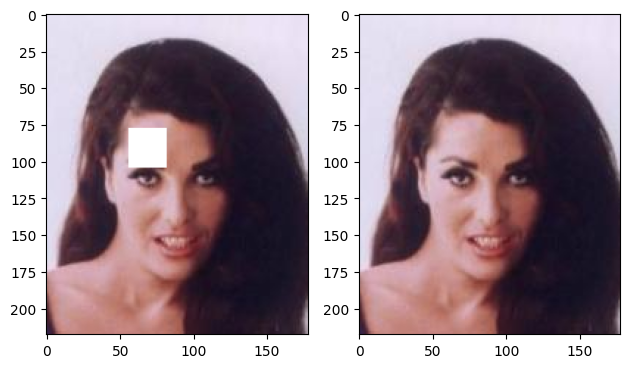

In [14]:
for i in range(10, 20):
    img1, img2 = train_dataset[i]
    
    plt.subplot(1, 2, 1)
    plt.imshow(img1.permute(1, 2, 0).numpy())
    
    plt.subplot(1, 2, 2)
    plt.imshow(img2.permute(1, 2, 0).numpy())
    
    plt.tight_layout()
    plt.show()

# Unet

In [ ]:
class UnetConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv_stack = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()
        )

    def forward(self, x):
        return self.conv_stack(x)



class Unet(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.encoder_1 = UnetConvBlock(3, 64)
        self.encoder_2 = UnetConvBlock(64, 128)
        self.encoder_3 = UnetConvBlock(128, 256)
        self.encoder_4 = UnetConvBlock(256, 512)
        self.encoder_5 = UnetConvBlock(512, 1024)

        self.decoder_4 = UnetConvBlock(1024, 512)
        self.decoder_3 = UnetConvBlock(512, 256)
        self.decoder_2 = UnetConvBlock(256, 128)
        self.decoder_1 = UnetConvBlock(128, 64)

        self.upconv_1 = nn.ConvTranspose2d(in_channels=1024, out_channels=512, kernel_size=2, stride=2)
        self.upconv_2 = nn.ConvTranspose2d(in_channels=512, out_channels=256, kernel_size=2, stride=2)
        self.upconv_3 = nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=2, stride=2)
        self.upconv_4 = nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=2, stride=2)


        self.output_conv = nn.Conv2d(64, 3, kernel_size=3, padding=1)

    def forward(self, x):
        x1_encoder = self.encoder_1(x)
        x2_encoder = self.encoder_2(self.pool(x1_encoder))
        x3_encoder = self.encoder_3(self.pool(x2_encoder))
        x4_encoder = self.encoder_4(self.pool(x3_encoder))
        x5_encoder = self.encoder_5(self.pool(x4_encoder))

        def match_and_concat(encoder_tensor, upconv_tensor):
            if upconv_tensor.shape[2:] != encoder_tensor.shape[2:]:
                diff_h = encoder_tensor.size()[2] - upconv_tensor.size()[2]
                diff_w = encoder_tensor.size()[3] - upconv_tensor.size()[3]

                upconv_tensor = F.pad(upconv_tensor, [
                    diff_w // 2, diff_w - diff_w // 2,
                    diff_h // 2, diff_h - diff_h // 2
                ])
            return torch.cat([encoder_tensor, upconv_tensor], dim=1)

        x1_decoder = self.decoder_4(match_and_concat(x4_encoder, self.upconv_1(x5_encoder)))
        x2_decoder = self.decoder_3(match_and_concat(x3_encoder, self.upconv_2(x1_decoder)))
        x3_decoder = self.decoder_2(match_and_concat(x2_encoder, self.upconv_3(x2_decoder)))
        x4_decoder = self.decoder_1(match_and_concat(x1_encoder, self.upconv_4(x3_decoder)))

        output = self.output_conv(x4_decoder)

        return output

In [ ]:
def train_loop(model, loader, loss_fn, optimizer, train_losses, batch_size, len_dataset, verbose=10):
    model.train()
    batch_losses = []


    for batch, (X, y) in enumerate(loader):
        if not is_xla:
            X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        pred = model(X)
        loss = loss_fn(pred, y)
        loss.backward()

        if is_xla:
            xm.optimizer_step(optimizer)
        else:
            optimizer.step()

        batch_losses.append(loss.item())

        if (batch + 1) % int(len_dataset/ batch_size / verbose) == 0:
            print(f'{(batch+1) * batch_size}/{len_dataset} | loss: {batch_losses[-1]:.5f}')

    avg_train_loss = sum(batch_losses) / len(batch_losses)
    print(f'Avg train loss: {avg_train_loss:.5f}')
    train_losses.append(avg_train_loss)

In [ ]:
def test_loop(model, loader, loss_fn, test_losses):
    model.eval()
    batch_losses = []
    dice_coefs = []
    tp_sum = fp_sum = fn_sum = tn_sum = 0
    total_loss = 0
    num_batches = 0
    
    with torch.no_grad():
        for batch, (X, y) in enumerate(loader):
            if not is_xla:
                X, y = X.to(device), y.to(device)

            pred = model(X)
            loss = loss_fn(pred, y)

            num_batches += 1
            total_loss += loss
            
        if is_xla:
            torch_xla.sync()

            
            
    avg_test_loss = (total_loss / num_batches).item()

    print()
    print(f'Avg test loss: {avg_test_loss:.5f}') 
    test_losses.append(avg_test_loss)
    return avg_test_loss

In [ ]:
train_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 50, 125, 175], size=20000, transform = get_transform, target_transform=target_transform)
test_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 50, 125, 175], size=20000, is_train=False, transform = get_transform, target_transform=target_transform)

In [ ]:
batch_size = 32
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, num_workers=2)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, num_workers=2)

len_dataset = len(train_dataloader.dataset)

if is_xla:
    train_dataloader = pl.MpDeviceLoader(train_dataloader, device)
    test_dataloader = pl.MpDeviceLoader(test_dataloader, device)

In [ ]:
model = Unet().to(device)
loss_fn = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, min_lr=1e-7, threshold=1e-4)
train_losses = []
test_losses = []

In [ ]:
num_epochs = 10

best_model = None
best_loss = float('inf')

In [ ]:
for i in range(num_epochs):
    print(f"Epoch {i + 1}")
    train_loop(model, train_dataloader, loss_fn, optimizer, train_losses, batch_size, len_dataset, verbose=50)
    val_loss = test_loop(model, test_dataloader, loss_fn, test_losses)
    if val_loss < best_loss:
        best_model = copy.deepcopy(model)
        best_loss = val_loss
    scheduler.step(val_loss)
    print('-' * 30)

In [ ]:
torch.save(best_model.state_dict(), f'autoencoder.pth')

In [ ]:
path = '/kaggle/input/models/slnkvdns/unet-ae/pytorch/default/4/autoencoder.pth'
model = Unet().to(device)
model.load_state_dict(torch.load(path, weights_only=True));

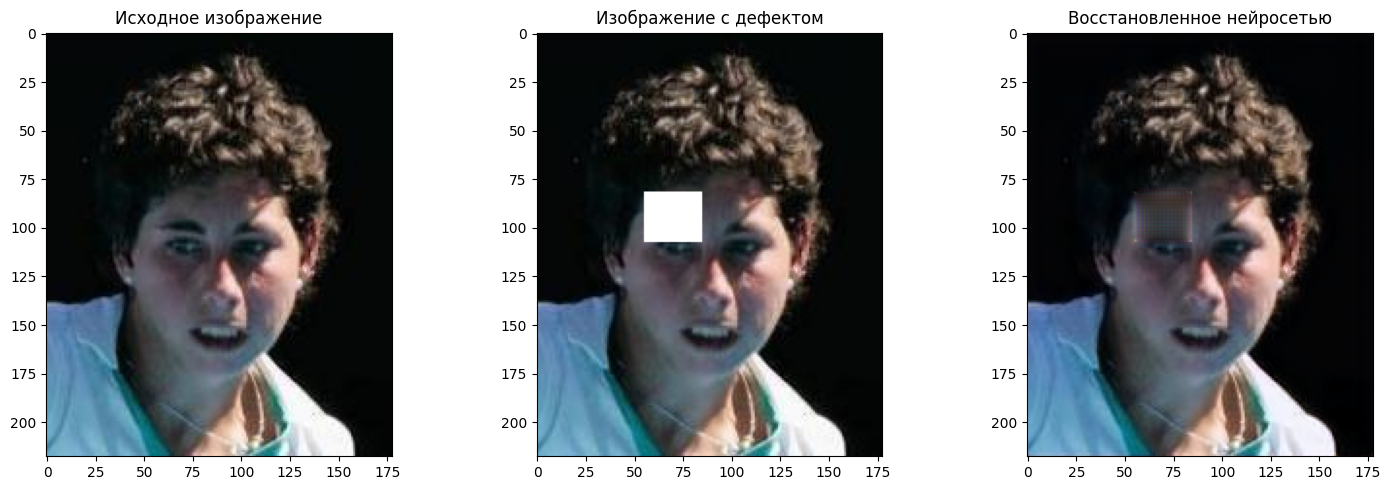

In [21]:
model.eval()
indices = np.random.choice(range(0, len(test_dataset)), size=10, replace=False)

for idx in indices:
    img_with_rect, img = test_dataset[idx]
    denoise_img = model(img_with_rect.to(device).unsqueeze(0))
    denoised_np_img = denoise_img[0].permute(1, 2, 0).cpu().detach().numpy()
    
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(img.permute(1, 2, 0).numpy())
    plt.title('Исходное изображение')
    
    plt.subplot(1, 3, 2)
    plt.imshow(img_with_rect.permute(1, 2, 0).numpy())
    plt.title('Изображение с дефектом')
    
    plt.subplot(1, 3, 3)
    plt.imshow(denoised_np_img)
    plt.title('Восстановленное нейросетью')
    
    plt.tight_layout()
    plt.show();

## Видим, что модель хорошо справляется с однотонной частью лица. Попробуем продолжить обучать на примерах, где белый прямоугольник будет чаще попадаться на местах с глазами, носом, ртом. Для этого мы просто уменьшим область, в которой он может появиться

In [ ]:
train_dataset_2 = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 75, 125, 175], size=20000, transform = get_transform, target_transform=target_transform)

In [ ]:
batch_size = 32
train_dataloader_2 = DataLoader(train_dataset_2, batch_size=batch_size, num_workers=2)

len_dataset = len(train_dataloader_2.dataset)

if is_xla:
    train_dataloader_2 = pl.MpDeviceLoader(train_dataloader_2, device)

In [ ]:
path = '/kaggle/input/models/slnkvdns/unet-ae/pytorch/default/4/autoencoder.pth'
model = Unet().to(device)
model.load_state_dict(torch.load(path, weights_only=True));

In [ ]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, min_lr=1e-7, threshold=1e-4)
train_losses = []
test_losses = []

In [ ]:
num_epochs = 10

best_model = None
best_loss = float('inf')

In [ ]:
for i in range(num_epochs):
    print(f"Epoch {i + 1}")
    train_loop(model, train_dataloader_2, loss_fn, optimizer, train_losses, batch_size, len_dataset, verbose=50)
    val_loss = test_loop(model, test_dataloader, loss_fn, test_losses)
    if val_loss < best_loss:
        best_model = copy.deepcopy(model)
        best_loss = val_loss
    scheduler.step(val_loss)
    print('-' * 30)

In [ ]:
torch.save(best_model.state_dict(), f'autoencoder_2.pth')

In [ ]:
path = '/kaggle/input/models/slnkvdns/unet-ae/pytorch/default/4/autoencoder_2.pth'
model = Unet().to(device)
model.load_state_dict(torch.load(path, weights_only=True));

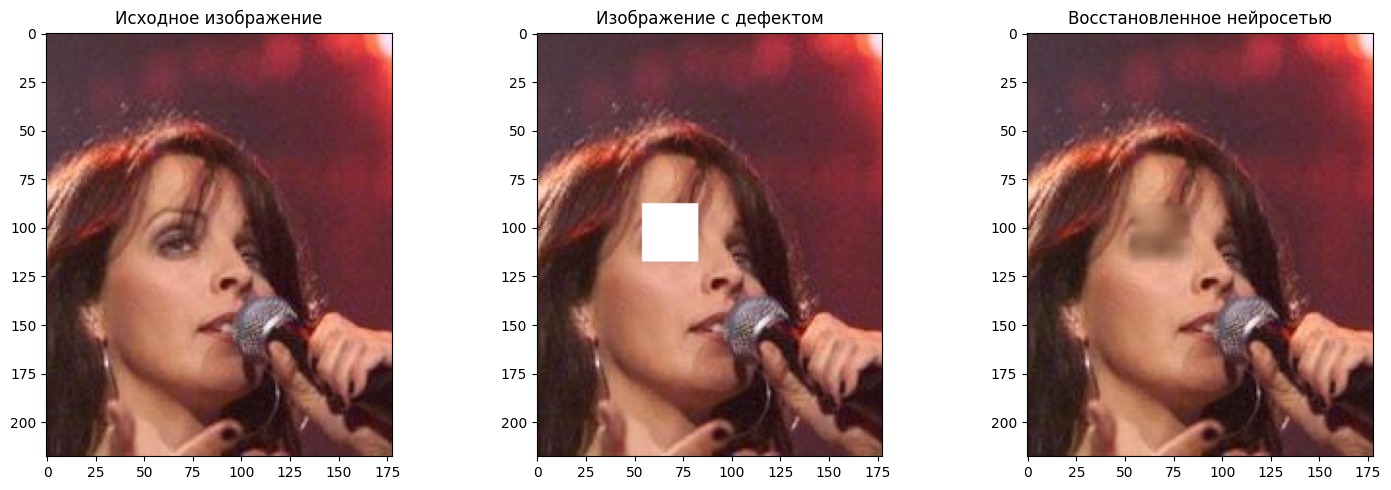

In [23]:
model.eval()
indices = np.random.choice(range(0, len(test_dataset)), size=10, replace=False)

for idx in indices:
    img_with_rect, img = test_dataset[idx]
    denoise_img = model(img_with_rect.to(device).unsqueeze(0))
    denoised_np_img = denoise_img[0].permute(1, 2, 0).cpu().detach().numpy()
    
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(img.permute(1, 2, 0).numpy())
    plt.title('Исходное изображение')
    
    plt.subplot(1, 3, 2)
    plt.imshow(img_with_rect.permute(1, 2, 0).numpy())
    plt.title('Изображение с дефектом')
    
    plt.subplot(1, 3, 3)
    plt.imshow(denoised_np_img)
    plt.title('Восстановленное нейросетью')
    
    plt.tight_layout()
    plt.show();

## Попуробуем ещё уменьшить пределы, в которых будет появляться прямоугольник

In [ ]:
train_dataset_3 = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 90, 125, 160], size=20000, transform = get_transform, target_transform=target_transform)

In [ ]:
batch_size = 32
train_dataloader_3 = DataLoader(train_dataset_3, batch_size=batch_size, num_workers=2)

len_dataset = len(train_dataloader_3.dataset)

if is_xla:
    train_dataloader_3 = pl.MpDeviceLoader(train_dataloader_3, device)

In [ ]:
path = '/kaggle/input/models/slnkvdns/unet-ae/pytorch/default/4/autoencoder_2.pth'
model = Unet().to(device)
model.load_state_dict(torch.load(path, weights_only=True));

In [ ]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, min_lr=1e-7, threshold=1e-4)
train_losses = []
test_losses = []

In [ ]:
num_epochs = 10

best_model = None
best_loss = float('inf')

In [ ]:
for i in range(num_epochs):
    print(f"Epoch {i + 1}")
    train_loop(model, train_dataloader_3, loss_fn, optimizer, train_losses, batch_size, len_dataset, verbose=50)
    val_loss = test_loop(model, test_dataloader, loss_fn, test_losses)
    if val_loss < best_loss:
        best_model = copy.deepcopy(model)
        best_loss = val_loss
    scheduler.step(val_loss)
    print('-' * 30)

In [ ]:
torch.save(best_model.state_dict(), f'autoencoder_3.pth')

In [ ]:
path = '../models/lab7/autoencoder_3.pth'
model = Unet().to(device)
model.load_state_dict(torch.load(path, weights_only=True));

## Финальный результат работы кастомного Unet

In [ ]:
test_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 50, 125, 175], size=40000, is_train=False, transform = get_transform, target_transform=target_transform)

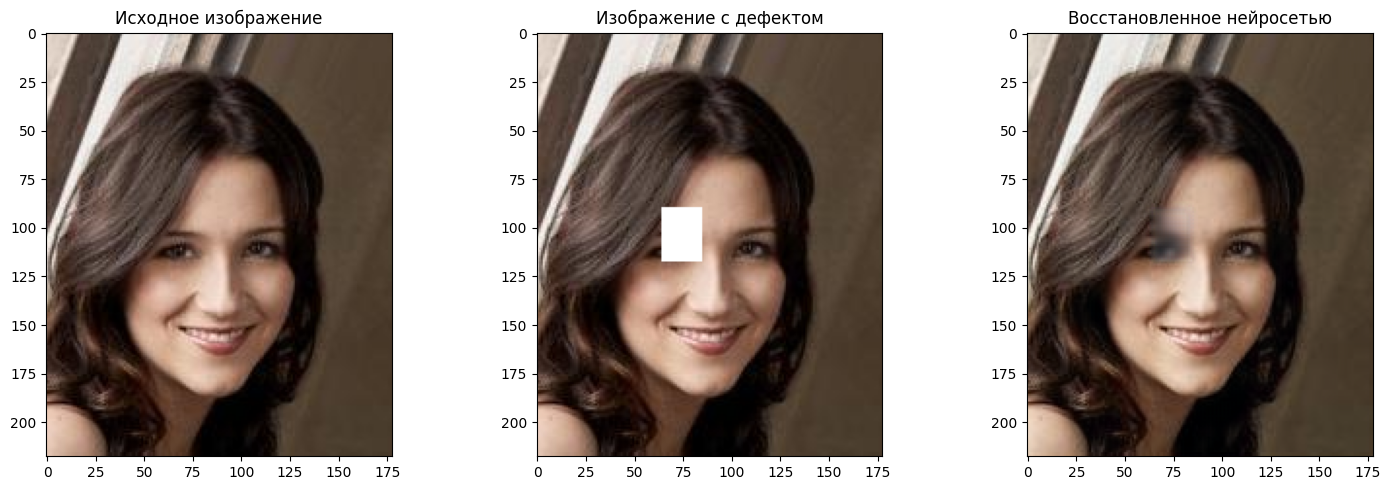

In [32]:
model.eval()
indices = np.random.choice(range(0, len(test_dataset)), size=20, replace=False)

for idx in indices:
    img_with_rect, img = test_dataset[idx]
    denoise_img = model(img_with_rect.to(device).unsqueeze(0))
    denoised_np_img = denoise_img[0].permute(1, 2, 0).cpu().detach().numpy().clip(0, 1)
    
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(img.permute(1, 2, 0).numpy())
    plt.title('Исходное изображение')
    
    plt.subplot(1, 3, 2)
    plt.imshow(img_with_rect.permute(1, 2, 0).numpy())
    plt.title('Изображение с дефектом')
    
    plt.subplot(1, 3, 3)
    plt.imshow(denoised_np_img)
    plt.title('Восстановленное нейросетью')
    
    plt.tight_layout()
    plt.show();

# Unet с предобученными энкодером (efficientnet-b1)

## Обучаем перывые 10 эпох на общей картине

In [ ]:
train_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 50, 125, 175], size=20000, transform = get_transform, target_transform=target_transform)
test_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 50, 125, 175], size=20000, is_train=False, transform = get_transform, target_transform=target_transform)

In [ ]:
batch_size = 32
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, num_workers=2)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, num_workers=2)

len_dataset = len(train_dataloader.dataset)

if is_xla:
    train_dataloader = pl.MpDeviceLoader(train_dataloader, device)
    test_dataloader = pl.MpDeviceLoader(test_dataloader, device)

In [ ]:
model = smp.Unet(
    encoder_name='timm-efficientnet-b1',
    encoder_weights='imagenet',
    classes=3
).to(device)

In [ ]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, min_lr=1e-7, threshold=1e-4)
train_losses = []
test_losses = []

In [ ]:
num_epochs = 10

best_model = None
best_loss = float('inf')

In [ ]:
for i in range(num_epochs):
    print(f"Epoch {i + 1}")
    train_loop(model, train_dataloader, loss_fn, optimizer, train_losses, batch_size, len_dataset, verbose=50)
    val_loss = test_loop(model, test_dataloader, loss_fn, test_losses)
    if val_loss < best_loss:
        best_model = copy.deepcopy(model)
        best_loss = val_loss
    scheduler.step(val_loss)
    print('-' * 30)

In [ ]:
best_model.save_pretrained('./timm-efficientnet-b0_1')

In [ ]:
model = best_model

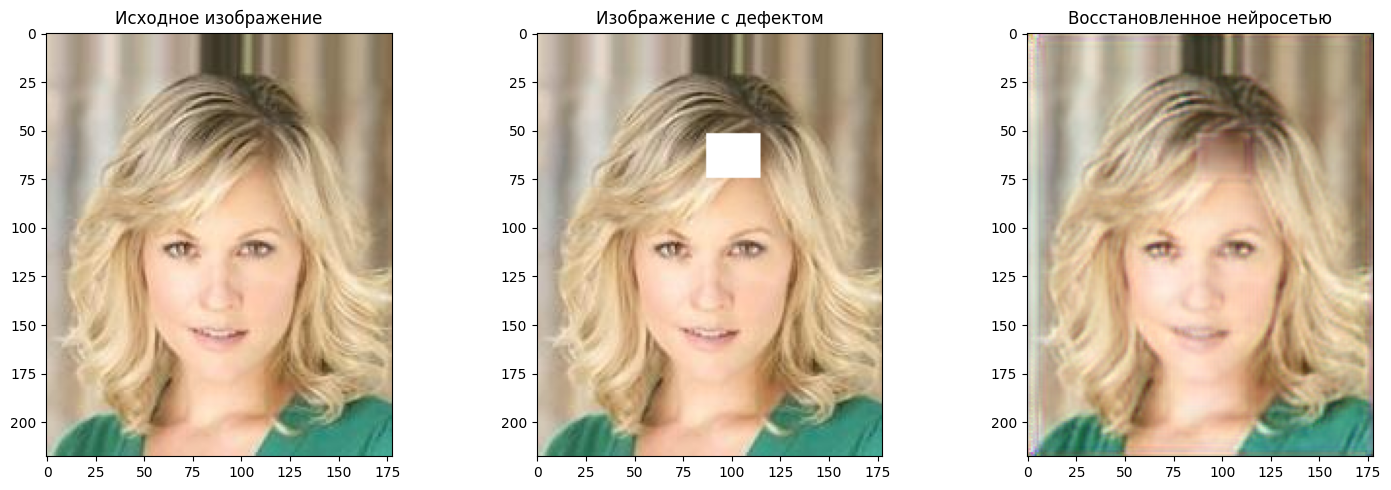

In [27]:
model.eval()
test_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 50, 125, 175], size=40000, is_train=False, transform = get_transform, target_transform=target_transform)
indices = np.random.choice(range(0, len(test_dataset)), size=10, replace=False)

for idx in indices:
    img_with_rect, img = test_dataset[idx]
    denoise_img = model(img_with_rect.to(device).unsqueeze(0))
    denoised_np_img = denoise_img[0].permute(1, 2, 0).cpu().detach().numpy()
    
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(img.permute(1, 2, 0).numpy())
    plt.title('Исходное изображение')
    
    plt.subplot(1, 3, 2)
    plt.imshow(img_with_rect.permute(1, 2, 0).numpy())
    plt.title('Изображение с дефектом')
    
    plt.subplot(1, 3, 3)
    plt.imshow(denoised_np_img)
    plt.title('Восстановленное нейросетью')
    
    plt.tight_layout()
    plt.show();

## Сужаем область появления белых прямоугольников

In [ ]:
train_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 75, 125, 175], size=20000, transform = get_transform, target_transform=target_transform)
test_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 75, 125, 175], size=20000, is_train=False, transform = get_transform, target_transform=target_transform)

In [ ]:
batch_size = 32
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, num_workers=2)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, num_workers=2)

len_dataset = len(train_dataloader.dataset)

if is_xla:
    train_dataloader = pl.MpDeviceLoader(train_dataloader, device)
    test_dataloader = pl.MpDeviceLoader(test_dataloader, device)

In [ ]:
model = smp.from_pretrained('timm-efficientnet-b0_1').to(device)

In [ ]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, min_lr=1e-7, threshold=1e-4)
train_losses = []
test_losses = []

In [ ]:
num_epochs = 10

best_model = None
best_loss = float('inf')

In [ ]:
for i in range(num_epochs):
    print(f"Epoch {i + 1}")
    train_loop(model, train_dataloader, loss_fn, optimizer, train_losses, batch_size, len_dataset, verbose=50)
    val_loss = test_loop(model, test_dataloader, loss_fn, test_losses)
    if val_loss < best_loss:
        best_model = copy.deepcopy(model)
        best_loss = val_loss
    scheduler.step(val_loss)
    print('-' * 30)

In [ ]:
model = best_model

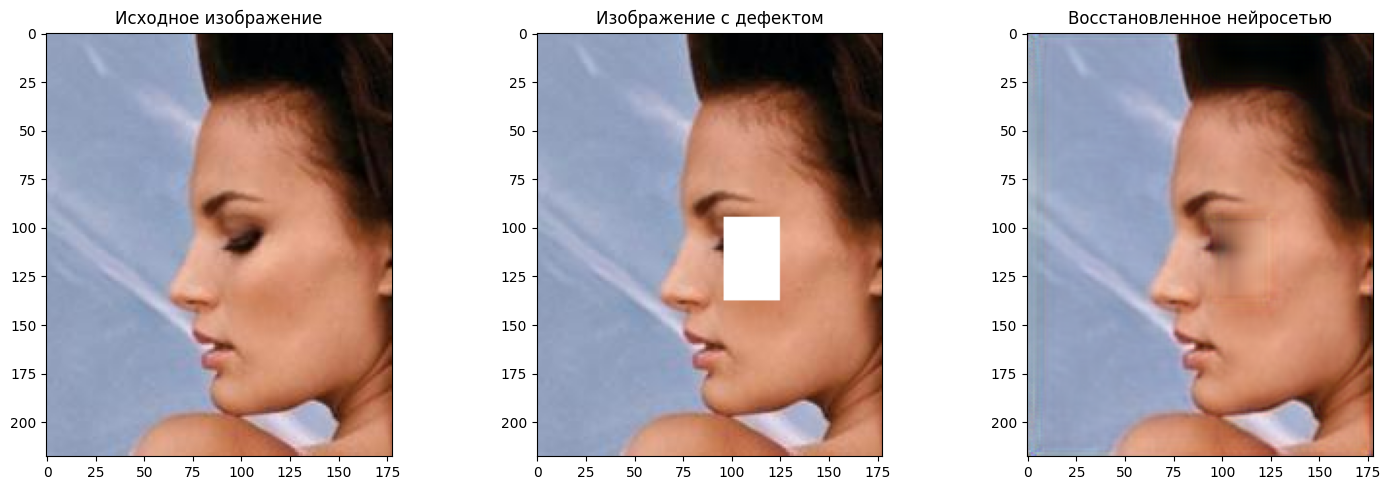

In [35]:
model.eval()
test_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 50, 125, 175], size=40000, is_train=False, transform = get_transform, target_transform=target_transform)
indices = np.random.choice(range(0, len(test_dataset)), size=10, replace=False)

for idx in indices:
    img_with_rect, img = test_dataset[idx]
    denoise_img = model(img_with_rect.to(device).unsqueeze(0))
    denoised_np_img = denoise_img[0].permute(1, 2, 0).cpu().detach().numpy()
    
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(img.permute(1, 2, 0).numpy())
    plt.title('Исходное изображение')
    
    plt.subplot(1, 3, 2)
    plt.imshow(img_with_rect.permute(1, 2, 0).numpy())
    plt.title('Изображение с дефектом')
    
    plt.subplot(1, 3, 3)
    plt.imshow(denoised_np_img)
    plt.title('Восстановленное нейросетью')
    
    plt.tight_layout()
    plt.show();

In [ ]:
best_model.save_pretrained('./timm-efficientnet-b0_2')

## Ещё сужаем

In [ ]:
train_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 90, 125, 160], size=20000, transform = get_transform, target_transform=target_transform)
test_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 90, 125, 160], size=20000, is_train=False, transform = get_transform, target_transform=target_transform)

In [ ]:
batch_size = 32
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, num_workers=2)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, num_workers=2)

len_dataset = len(train_dataloader.dataset)

if is_xla:
    train_dataloader = pl.MpDeviceLoader(train_dataloader, device)
    test_dataloader = pl.MpDeviceLoader(test_dataloader, device)

In [ ]:
model = smp.from_pretrained('timm-efficientnet-b0_2').to(device)

In [ ]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, min_lr=1e-7, threshold=1e-4)
train_losses = []
test_losses = []

In [ ]:
num_epochs = 10

best_model = None
best_loss = float('inf')

In [ ]:
for i in range(num_epochs):
    print(f"Epoch {i + 1}")
    train_loop(model, train_dataloader, loss_fn, optimizer, train_losses, batch_size, len_dataset, verbose=50)
    val_loss = test_loop(model, test_dataloader, loss_fn, test_losses)
    if val_loss < best_loss:
        best_model = copy.deepcopy(model)
        best_loss = val_loss
    scheduler.step(val_loss)
    print('-' * 30)

In [ ]:
model = best_model

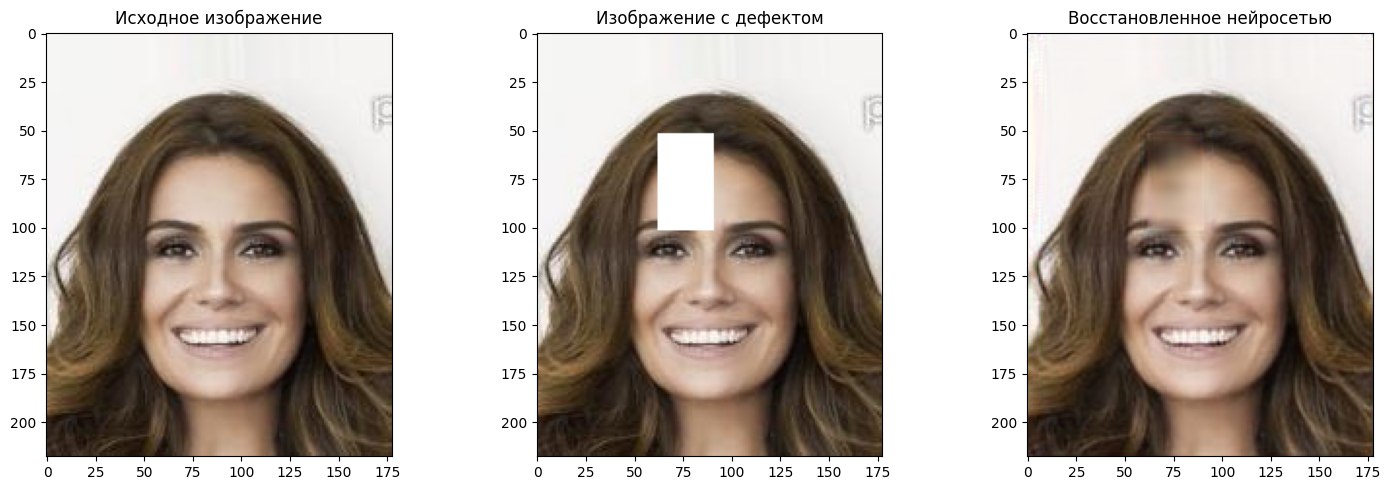

In [46]:
model.eval()
test_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 50, 125, 175], size=40000, is_train=False, transform = get_transform, target_transform=target_transform)
indices = np.random.choice(range(0, len(test_dataset)), size=30, replace=False)

for idx in indices:
    img_with_rect, img = test_dataset[idx]
    denoise_img = model(img_with_rect.to(device).unsqueeze(0))
    denoised_np_img = denoise_img[0].permute(1, 2, 0).cpu().detach().numpy()
    
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(img.permute(1, 2, 0).numpy())
    plt.title('Исходное изображение')
    
    plt.subplot(1, 3, 2)
    plt.imshow(img_with_rect.permute(1, 2, 0).numpy())
    plt.title('Изображение с дефектом')
    
    plt.subplot(1, 3, 3)
    plt.imshow(denoised_np_img)
    plt.title('Восстановленное нейросетью')
    
    plt.tight_layout()
    plt.show();

In [ ]:
best_model.save_pretrained('./timm-efficientnet-b0_3')

## Уменьшим lr, снова увеличим область появления шума

In [ ]:
train_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 75, 125, 175], size=20000, transform = get_transform, target_transform=target_transform)
test_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 75, 125, 175], size=20000, is_train=False, transform = get_transform, target_transform=target_transform)

In [ ]:
batch_size = 32
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, num_workers=2)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, num_workers=2)

len_dataset = len(train_dataloader.dataset)

if is_xla:
    train_dataloader = pl.MpDeviceLoader(train_dataloader, device)
    test_dataloader = pl.MpDeviceLoader(test_dataloader, device)

In [ ]:
model = smp.from_pretrained('timm-efficientnet-b0_3').to(device)

In [ ]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, min_lr=1e-7, threshold=1e-4)
train_losses = []
test_losses = []

In [ ]:
num_epochs = 10

best_model = None
best_loss = float('inf')

In [ ]:
for i in range(num_epochs):
    print(f"Epoch {i + 1}")
    train_loop(model, train_dataloader, loss_fn, optimizer, train_losses, batch_size, len_dataset, verbose=50)
    val_loss = test_loop(model, test_dataloader, loss_fn, test_losses)
    if val_loss < best_loss:
        best_model = copy.deepcopy(model)
        best_loss = val_loss
    scheduler.step(val_loss)
    print('-' * 30)

In [ ]:
model = best_model

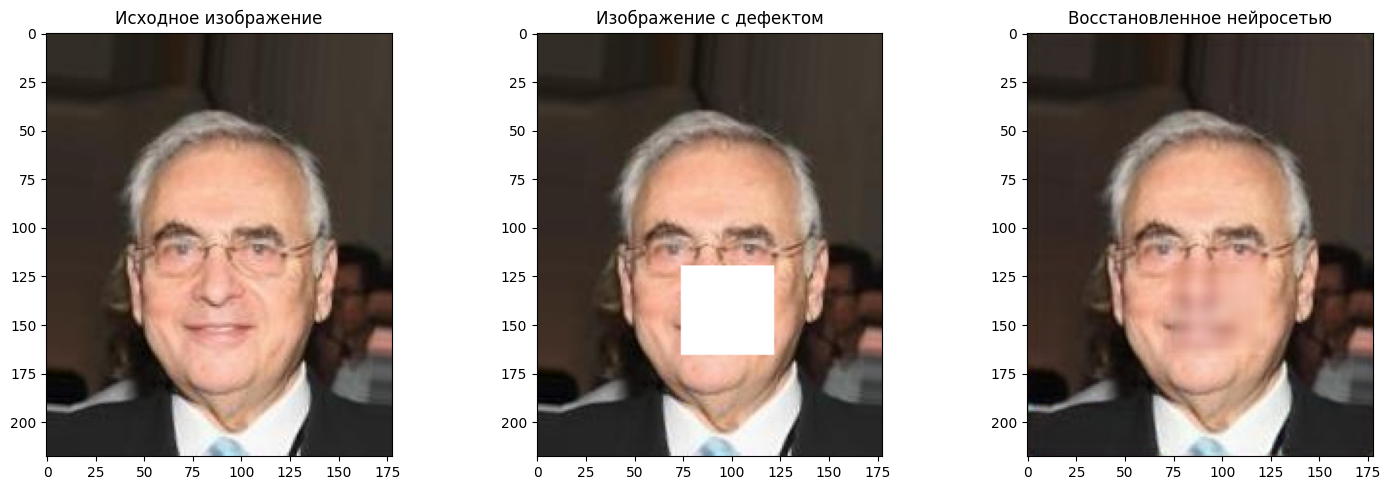

In [63]:
model.eval()
test_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 50, 125, 175], size=40000, is_train=False, transform = get_transform, target_transform=target_transform)
indices = np.random.choice(range(0, len(test_dataset)), size=10, replace=False)

for idx in indices:
    img_with_rect, img = test_dataset[idx]
    denoise_img = model(img_with_rect.to(device).unsqueeze(0))
    denoised_np_img = denoise_img[0].permute(1, 2, 0).cpu().detach().numpy()
    
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(img.permute(1, 2, 0).numpy())
    plt.title('Исходное изображение')
    
    plt.subplot(1, 3, 2)
    plt.imshow(img_with_rect.permute(1, 2, 0).numpy())
    plt.title('Изображение с дефектом')
    
    plt.subplot(1, 3, 3)
    plt.imshow(denoised_np_img)
    plt.title('Восстановленное нейросетью')
    
    plt.tight_layout()
    plt.show();

In [ ]:
best_model.save_pretrained('./timm-efficientnet-b0_4')

# Сравнение кастомного Unet, обученного с нуля и предобученного

In [ ]:
path = '/kaggle/working/autoencoder_5.pth'
model = Unet().to(device)
model.load_state_dict(torch.load(path, weights_only=True));

model_2 = smp.from_pretrained(
    '/kaggle/input/models/slnkvdns/unet-ae/pytorch/default/7/unet-efficientnet'
).to(device)

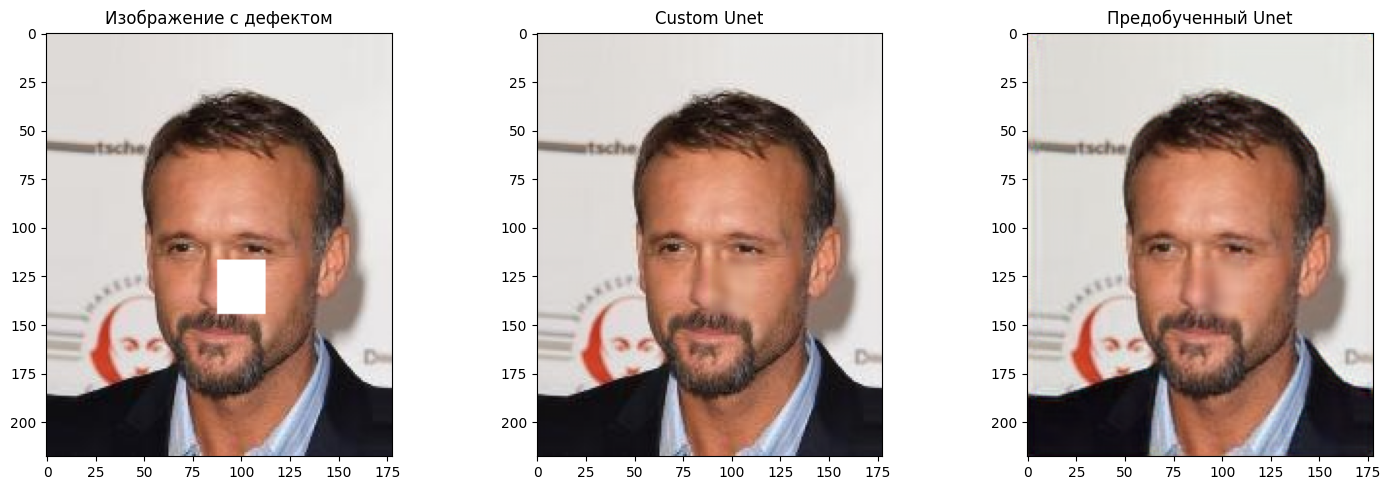

In [32]:
model.eval()
model_2.eval()
test_dataset = FaceDataset(img_dir, train_size=0.9, white_rect=[50, 75, 125, 175], size=40000, is_train=False, transform = get_transform, target_transform=target_transform)
indices = np.random.choice(range(0, len(test_dataset)), size=40, replace=False)

for idx in indices:
    img_with_rect, img = test_dataset[idx]
    denoise_img = model(img_with_rect.to(device).unsqueeze(0))
    denoised_np_img = denoise_img[0].permute(1, 2, 0).cpu().detach().numpy().clip(0, 1)

    denoise_img_2 = model_2(img_with_rect.to(device).unsqueeze(0))
    denoised_np_img_2 = denoise_img_2[0].permute(1, 2, 0).cpu().detach().numpy().clip(0, 1)
    
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(img_with_rect.permute(1, 2, 0).numpy())
    plt.title('Изображение с дефектом')
    
    plt.subplot(1, 3, 2)
    plt.imshow(denoised_np_img)
    plt.title('Custom Unet')

    plt.subplot(1, 3, 3)
    plt.imshow(denoised_np_img_2)
    plt.title('Предобученный Unet')
    
    plt.tight_layout()
    plt.show();